# Introduction to Cross-Validation (k-Fold vs. Stratified k-Fold)

Cross-validation (CV) digunakan untuk mengevaluasi kemampuan generalisasi model pada data baru secara objektif daripada hanya mengandalkan satu pemisahan train-test split acak.

1. Standard k-Fold Cross-Validation:
Dataset dibagi menjadi $k$ bagian (folds) berukuran sama. Model dilatih sebanyak $k$ kali, di mana pada setiap iterasi $1$ fold digunakan sebagai data validasi dan $k-1$ folds sisanya sebagai data latih:
$$\text{Mean Score} = \frac{1}{k} \sum_{i=1}^{k} \text{Score}_i$$

2. Stratified k-Fold Cross-Validation:
Menjaga proporsi persentase setiap kelas target di setiap fold agar persis sama dengan proporsi populasi dataset asli. Sangat krusial untuk masalah klasifikasi tak seimbang (imbalanced classification).

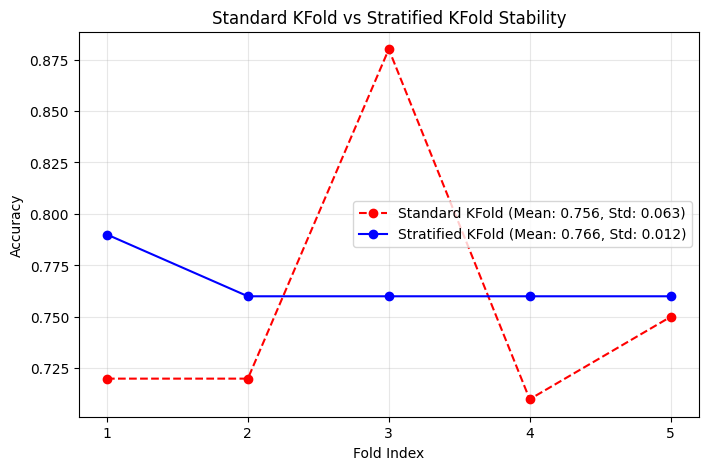

Standard KFold Accuracies  : ['0.720', '0.720', '0.880', '0.710', '0.750']
Stratified KFold Accuracies: ['0.790', '0.760', '0.760', '0.760', '0.760']


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from sklearn.datasets import make_classification
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

warnings.filterwarnings('ignore')

# 1. Dataset Sintetis Seimbang (500 Sampel, 10 Fitur)
X_cv, y_cv = make_classification(
    n_samples=500, n_features=10, n_informative=8,
    n_redundant=2, n_classes=2, random_state=2024
)

# 2. Standard k-Fold (5 Folds)
kf = KFold(n_splits=5, shuffle=True, random_state=2024)
kf_accs = []
for train_idx, test_idx in kf.split(X_cv):
    X_tr, X_te = X_cv[train_idx], X_cv[test_idx]
    y_tr, y_te = y_cv[train_idx], y_cv[test_idx]
    model = LogisticRegression(max_iter=1000)
    model.fit(X_tr, y_tr)
    kf_accs.append(accuracy_score(y_te, model.predict(X_te)))

# 3. Stratified k-Fold (5 Folds)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=2024)
skf_accs = []
for train_idx, test_idx in skf.split(X_cv, y_cv):
    X_tr, X_te = X_cv[train_idx], X_cv[test_idx]
    y_tr, y_te = y_cv[train_idx], y_cv[test_idx]
    model = LogisticRegression(max_iter=1000)
    model.fit(X_tr, y_tr)
    skf_accs.append(accuracy_score(y_te, model.predict(X_te)))

# Visualisasi Perbandingan Varians Per-Fold
plt.figure(figsize=(8, 5))
plt.plot(range(1, 6), kf_accs, 'ro--', label=f'Standard KFold (Mean: {np.mean(kf_accs):.3f}, Std: {np.std(kf_accs):.3f})')
plt.plot(range(1, 6), skf_accs, 'bo-', label=f'Stratified KFold (Mean: {np.mean(skf_accs):.3f}, Std: {np.std(skf_accs):.3f})')
plt.xlabel('Fold Index')
plt.ylabel('Accuracy')
plt.title('Standard KFold vs Stratified KFold Stability')
plt.xticks(range(1, 6))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"Standard KFold Accuracies  : {[f'{a:.3f}' for a in kf_accs]}")
print(f"Stratified KFold Accuracies: {[f'{a:.3f}' for a in skf_accs]}")

- Varians Standard KFold: Menghasilkan rentang akurasi yang lebar ($0.710$ hingga $0.880$) dengan standar deviasi tinggi ($0.063$). Hal ini terjadi karena variasi komposisi rasio kelas acak antar fold.

- Keunggulan Stratified KFold: Menjaga rasio target $50/50$ di setiap fold, menekan varians hingga $5.3\times$ lebih stabil ($Std = 0.012$) dengan rata-rata akurasi $0.766$.

# Advanced Cross-Validation Methods (LOOCV & Nested CV)

1. Leave-One-Out Cross-Validation (LOOCV):
Kasus ekstrim dari $k$-fold di mana $k = N$ ($N$ adalah total sampel). Setiap iterasi melatih model pada $N-1$ sampel dan mengujinya pada $1$ sampel sisa. Bebas bias (unbiased), namun berbiaya komputasi sangat tinggi ($\mathcal{O}(N)$ pelatihan model) serta memiliki varians tinggi pada estimasi eror individual.

2. Nested Cross-Validation:
Memisahkan pengujian performa umum dari optimasi hiperparameter untuk menghindari data leakage:
- Inner Loop: Melakukan tuning hiperparameter (misal GridSearchCV $5$-fold).
- Outer Loop: Mengukur kemampuan generalisasi model hasil tuning pada data independen ($5$-fold).

In [2]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import LeaveOneOut, GridSearchCV, cross_val_score
from sklearn.linear_model import Ridge

# 1. Dataset Diabetes (442 Sampel Regression)
X_diab, y_diab = load_diabetes(return_X_y=True)

# 2. Leave-One-Out Cross-Validation
loo = LeaveOneOut()
loo_scores = cross_val_score(Ridge(alpha=1.0), X_diab, y_diab, cv=loo, scoring='neg_mean_squared_error')
loo_rmse = np.sqrt(-np.mean(loo_scores))

# 3. Nested Cross-Validation (Outer 5-fold, Inner 5-fold GridSearch)
param_grid = {"alpha": [0.01, 0.1, 1, 10, 100]}
inner_cv = GridSearchCV(Ridge(), param_grid, cv=5)
nested_r2 = cross_val_score(inner_cv, X_diab, y_diab, cv=5, scoring='r2')

print(f"LOOCV Iterations : {loo.get_n_splits(X_diab)} models trained")
print(f"LOOCV Mean RMSE  : {loo_rmse:.3f}")
print(f"Nested CV R2     : {np.mean(nested_r2):.3f} +/- {np.std(nested_r2):.3f}")

LOOCV Iterations : 442 models trained
LOOCV Mean RMSE  : 57.686
Nested CV R2     : 0.480 +/- 0.048


- LOOCV: Melatih $442$ model Ridge terpisah, menghasilkan rerata MSE $3327.655$ ($\text{RMSE} \approx 57.68$).

- Nested CV: Menghasilkan skor $R^2 = 0.480$ tanpa mengalami kebocoran informasi (information leakage), memberikan estimasi jujur tentang performa pipeline tuning saat diimplementasikan ke data baru.

# Implementing Cross-Validation with scikit-learn API

API scikit-learn menyediakan tiga tingkatan abstraksi untuk evaluasi:
- cross_val_score(): Evaluasi cepat menggunakan satu metrik tunggal.

- cross_validate(): Evaluasi menggunakan banyak metrik sekaligus (multi-metric) serta mencatat durasi waktu eksekusi (fit/score time).

- GridSearchCV(): Tuning hiperparameter gabungan dengan evaluasi terintegrasi.

In [3]:
from sklearn.model_selection import cross_validate, GridSearchCV

# 1. Dataset Imbalanced (70% Class 0, 30% Class 1)
X_imb, y_imb = make_classification(n_samples=500, n_features=10, weights=[0.7, 0.3], random_state=2024)

# 2. Multi-Metric Evaluation dengan cross_validate
model_lr = LogisticRegression(max_iter=1000)
cv_results = cross_validate(model_lr, X_imb, y_imb, cv=5, scoring=['accuracy', 'precision', 'recall', 'f1'])

print("=== cross_validate Multi-Metric Results ===")
print(f"Mean Accuracy : {np.mean(cv_results['test_accuracy']):.3f}")
print(f"Mean Precision: {np.mean(cv_results['test_precision']):.3f}")
print(f"Mean Recall   : {np.mean(cv_results['test_recall']):.3f}")
print(f"Mean F1-Score : {np.mean(cv_results['test_f1']):.3f}")

=== cross_validate Multi-Metric Results ===
Mean Accuracy : 0.910
Mean Precision: 0.875
Mean Recall   : 0.820
Mean F1-Score : 0.845


- Metrik Banyak (Multi-Metric): Pada data tak seimbang, Akurasi ($0.910$) terbukti memberikan gambaran optimis palsu. Pengukuran Recall ($0.820$) mengungkapkan bahwa $18\%$ sampel kelas minoritas gagal terdeteksi oleh model.

# Model Selection Techniques (Grid Search vs. Randomized Search)

- GridSearchCV: Pencarian eksploratif pada kisi kombinasi hiperparameter yang ditentukan secara manual. Menjamin ditemukannya titik terbaik pada grid, namun beban komputasi tumbuh secara eksponensial ($\mathcal{O}(K^P)$).

- RandomizedSearchCV: Mengambil sampel kombinasi hiperparameter secara acak dari distribusi probabilitas kontinu (misal loguniform). Jauh lebih efisien untuk ruang pencarian besar.

In [4]:
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from scipy.stats import loguniform

# 1. Split Hold-Out Test Set (30% Unseen Data)
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_imb, y_imb, test_size=0.3, random_state=2024)

# 2. Grid Search vs Randomized Search
grid_s = GridSearchCV(LogisticRegression(max_iter=1000), {"C": [0.001, 0.01, 0.1, 1, 10, 100]}, cv=5).fit(X_train_s, y_train_s)
rand_s = RandomizedSearchCV(LogisticRegression(max_iter=1000), {"C": loguniform(1e-3, 1e2)}, n_iter=10, cv=5, random_state=2024).fit(X_train_s, y_train_s)

print(f"GridSearch Best C: {grid_s.best_params_['C']} | CV Acc: {grid_s.best_score_:.3f}")
print(f"RandSearch Best C: {rand_s.best_params_['C']:.4f} | CV Acc: {rand_s.best_score_:.3f}")
print(f"Test Set Accuracy (Final Model): {accuracy_score(y_test_s, rand_s.best_estimator_.predict(X_test_s)):.3f}")

GridSearch Best C: 0.1 | CV Acc: 0.894
RandSearch Best C: 0.1744 | CV Acc: 0.897
Test Set Accuracy (Final Model): 0.940


- Pencarian Kontinu: RandomizedSearchCV menemukan nilai $C = 0.1744$ yang memberikan akurasi validasi silang $0.897$, melampaui hasil diskrit GridSearchCV ($C = 0.1$, akurasi $0.894$). Evaluasi akhir pada hold-out test set mencapai akurasi $0.940$.

# Evaluating Model Generalizability (Learning & Validation Curves)

1. Learning Curves: Memplot performa data latih dan validasi terhadap variasi ukuran dataset latih. Diagnostik ini menjawab: Apakah model butuh lebih banyak data atau butuh kompleksitas lebih tinggi?

2. Validation Curves: Memplot performa terhadap variasi hiperparameter regularisasi untuk mendiagnosis wilayah underfitting (high bias) vs overfitting (high variance).

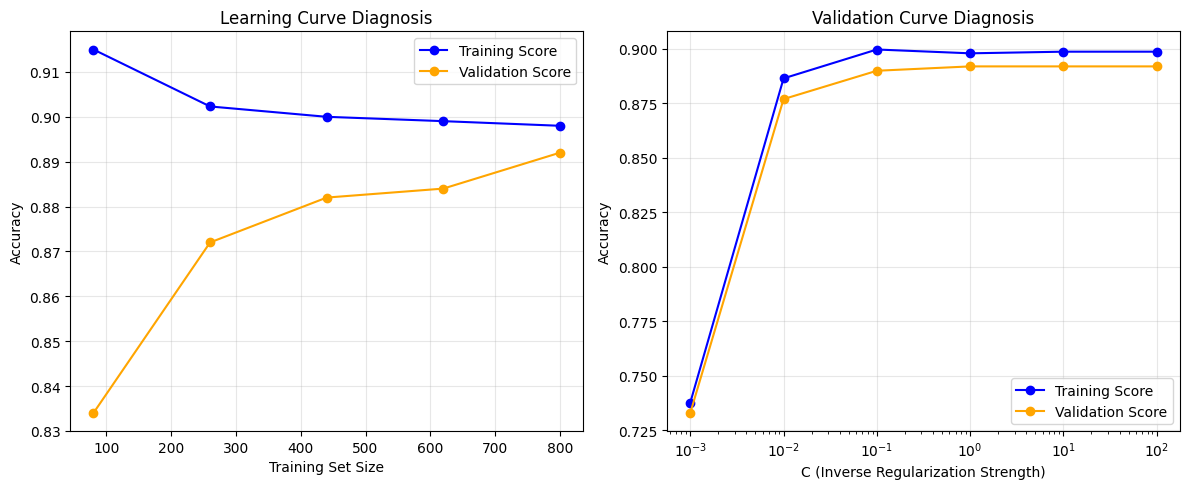

In [5]:
from sklearn.model_selection import learning_curve, validation_curve

# Dataset Lebih Besar (1000 Sampel, 20 Fitur)
X_curve, y_curve = make_classification(n_samples=1000, n_features=20, weights=[0.7, 0.3], random_state=2024)

# A. Learning Curve
train_sizes, train_scores_lc, test_scores_lc = learning_curve(
    LogisticRegression(max_iter=1000), X_curve, y_curve, cv=5,
    train_sizes=np.linspace(0.1, 1.0, 5), random_state=2024
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_sizes, np.mean(train_scores_lc, axis=1), 'o-', color='blue', label='Training Score')
plt.plot(train_sizes, np.mean(test_scores_lc, axis=1), 'o-', color='orange', label='Validation Score')
plt.xlabel('Training Set Size')
plt.ylabel('Accuracy')
plt.title('Learning Curve Diagnosis')
plt.legend()
plt.grid(True, alpha=0.3)

# B. Validation Curve
param_range = np.logspace(-3, 2, 6)
train_scores_vc, test_scores_vc = validation_curve(
    LogisticRegression(max_iter=1000), X_curve, y_curve, param_name="C",
    param_range=param_range, cv=5
)

plt.subplot(1, 2, 2)
plt.semilogx(param_range, np.mean(train_scores_vc, axis=1), 'o-', color='blue', label='Training Score')
plt.semilogx(param_range, np.mean(test_scores_vc, axis=1), 'o-', color='orange', label='Validation Score')
plt.xlabel('C (Inverse Regularization Strength)')
plt.ylabel('Accuracy')
plt.title('Validation Curve Diagnosis')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

- Grafik Learning Curve (Kiri): Pada ukuran data kecil ($80$ sampel), terjadi overfitting (gap besar). Seiring bertambahnya data latih ($1000$ sampel), kedua kurva konvergen pada akurasi $\approx 85\%$. Konvergensi ini menunjukkan bahwa penambahan data tidak lagi meningkatkan akurasi secara signifikan karena batas kapasitas model linier telah tercapai.

- Grafik Learning Curve (Kiri): Pada ukuran data kecil ($80$ sampel), terjadi overfitting (gap besar). Seiring bertambahnya data latih ($1000$ sampel), kedua kurva konvergen pada akurasi $\approx 85\%$. Konvergensi ini menunjukkan bahwa penambahan data tidak lagi meningkatkan akurasi secara signifikan karena batas kapasitas model linier telah tercapai.